<a href="https://colab.research.google.com/github/JoshuaBL2002/Advanced-Data-Science-Project-Repository/blob/main/notebooks/Air_Quality_NO2_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Air Quality NO₂ Prediction Project

## Section 1. Data Loading and Exploration

Dataset: Low-cost air quality sensors and reference monitoring stations in Rouen, France.

Objective: Investigate whether machine learning models can predict reference NO₂ concentrations using low-cost sensor measurements.

In [4]:
# Section 1.1.1 - Import Required Libraries
# Load standard scientific computing, visualization, and file management packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile

In [3]:
# Section 1.1.2 - Upload Dataset Archive
# Prompt user to upload the raw compressed dataset zip archive
from google.colab import files

uploaded = files.upload()

Saving Air quality low-cost sensors and monitoring stations NO2 raw dataset in Rouen (France).zip to Air quality low-cost sensors and monitoring stations NO2 raw dataset in Rouen (France) (1).zip


In [5]:
# Section 1.1.3 - Extract Dataset Archive
# Check for the specified dataset zip archive and automatically extract its CSV files
# Define the target zip path directly to avoid relying on the interactive 'uploaded' variable
zip_filename = "/content/Air quality low-cost sensors and monitoring stations NO2 raw dataset in Rouen (France).zip"
extract_destination = "/content/rouen_dataset"

# Extract zip file automatically
if os.path.exists(zip_filename):
    print(f"Extracting {os.path.basename(zip_filename)}...")
    with zipfile.ZipFile(zip_filename, "r") as zip_ref:
        zip_ref.extractall(extract_destination)

    # Walk through directory to find and list extracted CSVs
    print("Extracted CSV files:")
    for root, dirs, filenames in os.walk(extract_destination):
        for filename in filenames:
            if filename.endswith(".csv"):
                print(os.path.join(root, filename))
else:
    print(f"Dataset zip file not found at: {zip_filename}")

Extracting Air quality low-cost sensors and monitoring stations NO2 raw dataset in Rouen (France).zip...
Extracted CSV files:
/content/rouen_dataset/Air quality low-cost sensors and monitoring stations NO2 raw dataset in Rouen (France)/ASE5.csv
/content/rouen_dataset/Air quality low-cost sensors and monitoring stations NO2 raw dataset in Rouen (France)/ASE13.csv
/content/rouen_dataset/Air quality low-cost sensors and monitoring stations NO2 raw dataset in Rouen (France)/ASE12.csv
/content/rouen_dataset/Air quality low-cost sensors and monitoring stations NO2 raw dataset in Rouen (France)/ASE10.csv
/content/rouen_dataset/Air quality low-cost sensors and monitoring stations NO2 raw dataset in Rouen (France)/ASE11.csv
/content/rouen_dataset/Air quality low-cost sensors and monitoring stations NO2 raw dataset in Rouen (France)/ASE4.csv
/content/rouen_dataset/Air quality low-cost sensors and monitoring stations NO2 raw dataset in Rouen (France)/ASE6.csv
/content/rouen_dataset/Air quality lo

In [6]:
# Section 1.1.4 - Quick Dataset Check
# Perform a preliminary discovery of individual sensor CSV files and print their basic row counts
import glob
import os

sensor_names = [
    "ASE4", "ASE5", "ASE6", "ASE7", "ASE8",
    "ASE10", "ASE11", "ASE12", "ASE13"
]

sensor_data = {}

for sensor in sensor_names:
    matches = glob.glob(
        f"/content/rouen_dataset/**/{sensor}.csv",
        recursive=True
    )

    if not matches:
        print(f"Missing dataset: {sensor}")
        continue

    temp = pd.read_csv(matches[0], sep=";")
    temp["Sensor_ID"] = sensor
    sensor_data[sensor] = temp

    print(f"{sensor}: {len(temp)} observations")

print("Datasets loaded:", len(sensor_data))

ASE4: 3719 observations
ASE5: 3740 observations
ASE6: 3720 observations
ASE7: 3600 observations
ASE8: 3356 observations
ASE10: 3739 observations
ASE11: 1871 observations
ASE12: 3619 observations
ASE13: 2855 observations
Datasets loaded: 9


In [84]:
# Section 1.2 - Load All Nine ASE Sensor Datasets
# Iterate, read, and merge all low-cost sensor CSV files with semicolon separator
import os
import pandas as pd

# Define the base directory containing the extracted sensor CSV files
extract_destination = "/content/rouen_dataset"

# Specify the list of all nine low-cost sensor nodes
sensor_names = [
    "ASE4", "ASE5", "ASE6",
    "ASE7", "ASE8", "ASE10",
    "ASE11", "ASE12", "ASE13"
]

# Create a dictionary to hold individual sensor DataFrames
sensor_data = {}

# Iterate through each sensor to locate and read its CSV file
for sensor in sensor_names:
    filename = f"{sensor}.csv"
    file_path = None

    # Walk recursively through the destination folder to find the CSV file
    for root, dirs, files in os.walk(extract_destination):
        if filename in files:
            file_path = os.path.join(root, filename)
            break

    # Skip to next sensor if current file is missing
    if file_path is None:
        print(f"File not found: {filename}")
        continue

    # Read dataset using semicolon as column separator
    temp_df = pd.read_csv(file_path, sep=";")

    # Track the sensor identifier for each record
    temp_df["Sensor_ID"] = sensor

    # Store inside our sensor data collection dictionary
    sensor_data[sensor] = temp_df

    print(f"{sensor}: {len(temp_df)} rows loaded")

# Confirm that all 9 expected datasets have been loaded
print("\nTotal datasets loaded:", len(sensor_data))

if len(sensor_data) != 9:
    raise ValueError("Not all nine sensor datasets were found.")

# Concatenate all individual sensor DataFrames into a single unified DataFrame
df = pd.concat(sensor_data.values(), ignore_index=True)

print("\nCombined dataset dimensions:", df.shape)

# Display the top 5 records of the combined dataset
display(df.head())

ASE4: 3719 rows loaded
ASE5: 3740 rows loaded
ASE6: 3720 rows loaded
ASE7: 3600 rows loaded
ASE8: 3356 rows loaded
ASE10: 3739 rows loaded
ASE11: 1871 rows loaded
ASE12: 3619 rows loaded
ASE13: 2855 rows loaded

Total datasets loaded: 9

Combined dataset dimensions: (30219, 15)


,date,ASE_NO2,ASE_NO,ASE_CO,ASE_Ox,ASE_T,ASE_HR,ASE_PA,SUD3_NO2,SUD3_NO,QDP_NO,QDP_NO2,QDP_CO,Location,Sensor_ID
0,2021-10-21 09:00,29260.45956,41784.20221,40379.02022,29097.00735,15.757992,61.396328,1010.553819,10.3,3.8,12.5,18.5,0.146,SUD3,ASE4
1,2021-10-21 10:00,NaN,41850.04167,40377.16667,29089.93750,17.221213,59.655553,1010.864815,9.2,4.2,16.1,19.8,0.146,SUD3,ASE4
2,2021-10-21 11:00,NaN,41810.25000,40351.71875,29047.67188,16.948157,62.823097,1011.373264,12.8,6.4,15.3,20.1,0.147,SUD3,ASE4
3,2021-10-21 12:00,NaN,42027.21232,40504.16636,29013.68566,16.563096,66.366573,1012.087500,33.5,33.0,42.3,42.5,0.211,SUD3,ASE4
4,2021-10-21 13:00,NaN,42541.39063,40830.34091,28971.16903,17.322202,66.408701,1012.443750,62.6,79.7,70.4,53.1,0.248,SUD3,ASE4


In [85]:
# Section 1.3- Aggregate Observation Summary by Sensor
# Check the contribution of each individual sensor ID within our unified DataFrame
# Count the number of recorded observations for each sensor node
sensor_summary = (
    df.groupby("Sensor_ID")
    .size()
    .reset_index(name="Observations")
)

# Render the summarized observations table
display(sensor_summary)

# Print the absolute total observations across all sensors
print("Total observations:", len(df))

,Sensor_ID,Observations
0,ASE10,3739
1,ASE11,1871
2,ASE12,3619
3,ASE13,2855
4,ASE4,3719
5,ASE5,3740
6,ASE6,3720
7,ASE7,3600
8,ASE8,3356


Total observations: 30219


In [86]:
# Section 1.4 - Validate Column Mappings and Station Distributions
# Review individual schemas and build a distribution matrix mapping locations and sensor nodes
# Print column layouts for each sensor to verify feature consistency
for sensor, dataset in sensor_data.items():
    print(f"\n{sensor} Column Layout:")
    print(dataset.columns.tolist())

# Generate a cross-tabulation comparing sensor node vs location
display(
    pd.crosstab(df["Sensor_ID"], df["Location"])
)


ASE4 Column Layout:
['date', 'ASE_NO2', 'ASE_NO', 'ASE_CO', 'ASE_Ox', 'ASE_T', 'ASE_HR', 'ASE_PA', 'SUD3_NO2', 'SUD3_NO', 'QDP_NO', 'QDP_NO2', 'QDP_CO', 'Location', 'Sensor_ID']

ASE5 Column Layout:
['date', 'ASE_NO2', 'ASE_NO', 'ASE_CO', 'ASE_Ox', 'ASE_T', 'ASE_HR', 'ASE_PA', 'SUD3_NO2', 'SUD3_NO', 'QDP_NO', 'QDP_NO2', 'QDP_CO', 'Location', 'Sensor_ID']

ASE6 Column Layout:
['date', 'ASE_NO2', 'ASE_NO', 'ASE_CO', 'ASE_Ox', 'ASE_T', 'ASE_HR', 'ASE_PA', 'SUD3_NO2', 'SUD3_NO', 'QDP_NO', 'QDP_NO2', 'QDP_CO', 'Location', 'Sensor_ID']

ASE7 Column Layout:
['date', 'ASE_NO2', 'ASE_NO', 'ASE_CO', 'ASE_Ox', 'ASE_T', 'ASE_HR', 'ASE_PA', 'SUD3_NO2', 'SUD3_NO', 'QDP_NO', 'QDP_NO2', 'QDP_CO', 'Location', 'Sensor_ID']

ASE8 Column Layout:
['date', 'ASE_NO2', 'ASE_NO', 'ASE_CO', 'ASE_Ox', 'ASE_T', 'ASE_HR', 'ASE_PA', 'SUD3_NO2', 'SUD3_NO', 'QDP_NO', 'QDP_NO2', 'QDP_CO', 'Location', 'Sensor_ID']

ASE10 Column Layout:
['date', 'ASE_NO2', 'ASE_NO', 'ASE_CO', 'ASE_Ox', 'ASE_T', 'ASE_HR', 'ASE_PA', 'SUD

Location,QDP,SUD3
Sensor_ID,,
ASE10,1291,2445
ASE11,1871,0
ASE12,883,2447
ASE13,1561,1266
ASE4,2445,983
ASE5,1436,2303
ASE6,0,3720
ASE7,2161,1438
ASE8,3356,0


In [ ]:
# Section 1.5 - Dataset Inspection & Null Value Metrics
# Perform structural checks on the complete merged dataframe, showing data types and null counts
# Print the dimensions (rows, columns) of the loaded ASE4 DataFrame
print("Dataset dimensions:", df.shape)

# List all columns present in the dataset
print("\nColumn names:")
print(df.columns.tolist())

# Display data types, memory usage, and non-null counts per column
print("\nData types:")
df.info()

# Display the count of missing (NaN) values for each column
print("\nMissing values:")
display(df.isnull().sum())

# Section 2 - Data Preprocessing

This section prepares the air quality sensor data for machine learning by examining missing values, checking duplicates, converting data types, and creating a single reference NO₂ target variable.

In [95]:
# Section 2.1 - Combine Sensor Datasets and Create Target
# Concatenate all sensor DataFrames and construct the aligned reference target
all_sensors = pd.concat(
    sensor_data.values(),
    ignore_index=True
)

# Create the reference NO2 target based on the monitoring station location
all_sensors["Reference_NO2"] = np.where(
    all_sensors["Location"] == "SUD3",
    all_sensors["SUD3_NO2"],
    np.where(
        all_sensors["Location"] == "QDP",
        all_sensors["QDP_NO2"],
        np.nan
    )
)

# Convert reference measurements to numeric type
all_sensors["Reference_NO2"] = pd.to_numeric(
    all_sensors["Reference_NO2"],
    errors="coerce"
)

# Prepare timestamps (using 'date' column)
all_sensors["date"] = pd.to_datetime(
    all_sensors["date"],
    errors="coerce"
)

# Remove observations without a valid target or timestamp
combined_clean = all_sensors.dropna(
    subset=["Reference_NO2", "date"]
).copy()

# Remove duplicate records within the same sensor
combined_clean = combined_clean.drop_duplicates()

print("Combined dataset:", combined_clean.shape)

display(
    combined_clean.groupby("Sensor_ID").size()
)

Combined dataset: (28739, 16)


,0
Sensor_ID,
ASE10,3549
ASE11,1864
ASE12,3318
ASE13,2810
ASE4,3246
ASE5,3518
ASE6,3500
ASE7,3587
ASE8,3347


In [96]:
# Section 2.2 - Analyze Missing Values
# Assess the volume and percentage of missing values per variable across the combined data
missing_values = df.isnull().sum()

# Calculate percentage of missing values
missing_percentage = (missing_values / len(df)) * 100

# Display results
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage (%)": missing_percentage
})

display(missing_summary)

,Missing Values,Percentage (%)
date,0,0.000000
ASE_NO2,1848,6.115358
ASE_NO,1202,3.977630
ASE_CO,1379,4.563354
ASE_Ox,1321,4.371422
ASE_T,1274,4.215891
ASE_HR,1274,4.215891
ASE_PA,1311,4.338330
SUD3_NO2,1760,5.824150
SUD3_NO,1760,5.824150


In [97]:
# Section 2.3 - Count Duplicate Rows
# Verify if duplicate observations exist in the merged dataframe prior to removal
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


In [98]:
# Section 2.4 - Inspect Merged Columns and Samples
# Print the available feature set and preview the initial rows of the merged data
print(df.columns.tolist())

# Display the first five records
display(df.head())

['date', 'ASE_NO2', 'ASE_NO', 'ASE_CO', 'ASE_Ox', 'ASE_T', 'ASE_HR', 'ASE_PA', 'SUD3_NO2', 'SUD3_NO', 'QDP_NO', 'QDP_NO2', 'QDP_CO', 'Location', 'Sensor_ID']


,date,ASE_NO2,ASE_NO,ASE_CO,ASE_Ox,ASE_T,ASE_HR,ASE_PA,SUD3_NO2,SUD3_NO,QDP_NO,QDP_NO2,QDP_CO,Location,Sensor_ID
0,2021-10-21 09:00,29260.45956,41784.20221,40379.02022,29097.00735,15.757992,61.396328,1010.553819,10.3,3.8,12.5,18.5,0.146,SUD3,ASE4
1,2021-10-21 10:00,NaN,41850.04167,40377.16667,29089.93750,17.221213,59.655553,1010.864815,9.2,4.2,16.1,19.8,0.146,SUD3,ASE4
2,2021-10-21 11:00,NaN,41810.25000,40351.71875,29047.67188,16.948157,62.823097,1011.373264,12.8,6.4,15.3,20.1,0.147,SUD3,ASE4
3,2021-10-21 12:00,NaN,42027.21232,40504.16636,29013.68566,16.563096,66.366573,1012.087500,33.5,33.0,42.3,42.5,0.211,SUD3,ASE4
4,2021-10-21 13:00,NaN,42541.39063,40830.34091,28971.16903,17.322202,66.408701,1012.443750,62.6,79.7,70.4,53.1,0.248,SUD3,ASE4


In [99]:
# Section 2.5 - Filter Invalid Targets and Drop Duplicates
# Cleanse the dataset by removing rows missing the reference target and dropping duplicates
df_clean = combined_clean.copy()

# Create the dependent variable
df_clean["Reference_NO2"] = np.where(
    df_clean["Location"] == "SUD3",
    df_clean["SUD3_NO2"],
    np.where(
        df_clean["Location"] == "QDP",
        df_clean["QDP_NO2"],
        np.nan
    )
)

# 1. Handle missing target values
initial_len = len(df_clean)
df_clean = df_clean.dropna(subset=["Reference_NO2"])
print(f"Dropped {initial_len - len(df_clean)} rows due to missing Reference_NO2 target values.")

# 2. Handle duplicates
duplicates_count = df_clean.duplicated().sum()
if duplicates_count > 0:
    df_clean = df_clean.drop_duplicates()
    print(f"Dropped {duplicates_count} duplicate rows.")
else:
    print("No duplicate rows found to drop.")

# Display the cleaned result
display(df_clean[["Location", "Reference_NO2"]].head(10))

Dropped 1480 rows due to missing Reference_NO2 target values.
No duplicate rows found to drop.


,Location,Reference_NO2
0,SUD3,10.3
1,SUD3,9.2
2,SUD3,12.8
3,SUD3,33.5
4,SUD3,62.6
5,SUD3,64.4
6,SUD3,79.1
7,SUD3,78.7
8,SUD3,100.1
9,SUD3,83.4


In [100]:
# Section 2.6 - Parse and Validate DateTime Column
# Inspect the date parsing process and handle any parsing failures explicitly
# Note: Modified to parse the 'date' column as there is no 'DateTime' column
df_clean['date'] = pd.to_datetime(df_clean['date'], errors='coerce')
failed_dates = df_clean['date'].isnull().sum()
print(f"Number of timestamps that failed to parse: {failed_dates}")
if failed_dates > 0:
    df_clean = df_clean.dropna(subset=['date'])
    print(f"Dropped {failed_dates} rows with invalid date formats.")

Number of timestamps that failed to parse: 0


# 3. Exploratory Data Analysis (EDA)

This section investigates patterns and relationships in the
air quality sensor data using statistical summaries and
visualisations.

The analysis focuses on NO₂ concentrations, differences
between monitoring stations, and relationships between
sensor measurements and reference NO₂ concentrations.

In [ ]:
### 3.1 Distribution of Reference NO₂
# Calculate and display descriptive statistics (mean, median, standard deviation, and range)
# for the compiled reference NO₂ target variable.
display(df_clean["Reference_NO2"].describe())

# Visualize the frequency distribution of Reference_NO2 using a histogram.
# The Kernel Density Estimate (KDE) curve helps identify skewness and overall shape.
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df_clean,
    x="Reference_NO2",
    bins=30,
    kde=True
)

plt.title("Distribution of Reference NO₂ Concentrations")
plt.xlabel("Reference_NO2 (µg/m³)")
plt.ylabel("Frequency")
plt.show()

### Observation & Discussion:
- **Distribution of Reference NO₂**: The distribution of reference NO₂ concentration is right-skewed, showing a high density of measurements concentrated around low to moderate values (between 10 µg/m³ and 35 µg/m³).
- **Outliers**: There is a long tail extending up to 100+ µg/m³, which represents periods of high air pollution or transient local emission spikes. These outliers are critical for machine learning since capturing extreme events is an important capability for environmental prediction models.

In [ ]:
### 3.2 Comparison Across Stations
# Use a box plot to examine the distribution of the target variable grouped by physical location.
# This visualizes station-specific medians, quartiles, and potential outliers.
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df_clean,
    x="Location",
    y="Reference_NO2"
)

plt.title("Reference NO₂ by Monitoring Station")
plt.xlabel("Monitoring Station")
plt.ylabel("Reference NO₂ Concentration")
plt.show()

### Observation & Discussion:
- **Comparison by Monitoring Station**: The boxplot shows the overall median concentration of NO₂ is slightly higher at the QDP station compared to SUD3.
- **Variability**: QDP displays a wider interquartile range (IQR), suggesting more fluctuating conditions, while SUD3 features a more compressed distribution with several high-value outliers.

In [ ]:
### 3.3 Correlation Analysis
# Filter for numerical columns to measure linear relationships between variables.
numeric_data = df_clean.select_dtypes(include=["number"])

# Compute Pearson correlation coefficients.
correlation_matrix = numeric_data.corr()

# Plot a annotated heatmap to highlight dependencies between sensor nodes and target values.
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Variables")
plt.show()

### Observation & Discussion:
- **Full Correlation Analysis**: Highly strong correlations are observed between co-located measurements.
- **Target Correlation**: The new heatmap focuses strictly on potential features (predictors) like the raw sensor voltages/resistances, temperature, and relative humidity against the target `Reference_NO2` variable. This prevents leakage of unaligned reference station variables.

In [ ]:
### 3.3.1 Predictor-Only Correlation Heatmap
# Filter columns to isolate only intended model predictors (e.g., sensor inputs, temperature, humidity) and the target variable
predictor_cols = [col for col in numeric_data.columns if not any(x in col for x in ['SUD3_NO2', 'QDP_NO2', 'SUD3_O3', 'QDP_O3']) or col == 'Reference_NO2']

plt.figure(figsize=(10, 6))
sns.heatmap(
    numeric_data[predictor_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Predictor vs Target Correlation Matrix")
plt.show()

In [ ]:
### 3.4 Temporal Trends
# Explicitly convert DateTime column to pandas datetime objects to prevent sorting and formatting errors
df_clean['DateTime'] = pd.to_datetime(df_clean['DateTime'], errors='coerce')

# Sort the dataset chronologically
df_time = df_clean.dropna(subset=['DateTime']).sort_values('DateTime')

# Draw the continuous trend of Reference_NO2 over time
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=df_time,
    x="DateTime",
    y="Reference_NO2"
)

plt.title("Reference NO₂ Concentrations Over Time")
plt.xlabel("Date and Time")
plt.ylabel("Reference NO₂ Concentration")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
### 3.5 Multi-Sensor Comparison (ASE4, ASE5, ASE6)
# Load additional datasets to establish comparisons across multiple low-cost sensors
ase_datasets = {}
for sensor_name in ["ASE4", "ASE5", "ASE6"]:
    # Try to find file paths dynamically in extraction destination
    file_path = None
    for root, dirs, filenames in os.walk(extract_destination):
        for filename in filenames:
            if filename == f"{sensor_name}.csv":
                file_path = os.path.join(root, filename)
                break
    if file_path:
        print(f"Loading {sensor_name} from {file_path}")
        temp_df = pd.read_csv(file_path, sep=";")
        temp_df['Sensor_ID'] = sensor_name
        # Standardize target alignment inside each sensor
        temp_df["Reference_NO2"] = np.where(
            temp_df["Location"] == "SUD3",
            temp_df["SUD3_NO2"],
            np.where(temp_df["Location"] == "QDP", temp_df["QDP_NO2"], np.nan)
        )
        ase_datasets[sensor_name] = temp_df.dropna(subset=["Reference_NO2"])

# Combine datasets for comparative visualization
if len(ase_datasets) > 0:
    combined_df = pd.concat(ase_datasets.values(), ignore_index=True)
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=combined_df, x="Sensor_ID", y="Reference_NO2", hue="Location")
    plt.title("Comparison of Reference NO₂ across Sensors ASE4, ASE5, and ASE6")
    plt.ylabel("Reference NO₂ Concentration (µg/m³)")
    plt.show()
else:
    print("Could not locate datasets for ASE5 and ASE6 for comparison.")

#Section 4

In [8]:
# Section 4.1 - Machine Learning Setup

# Import necessary data manipulation libraries
import pandas as pd
import numpy as np

# Import Scikit-Learn regressors
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)
# Import imputation and pipeline components
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Define the target variable (dependent variable to predict)
target = "Reference_NO2"

# Define the list of predictor variables (independent features)
features = [
    "ASE_NO2",
    "ASE_NO",
    "ASE_CO",
    "ASE_Ox",
    "ASE_T",
    "ASE_HR",
    "ASE_PA"
]

# Create a working copy of the cleaned dataframe with fallback safety
if "df_clean" in globals():
    model_df = df_clean.copy()
elif "combined_clean" in globals():
    model_df = combined_clean.copy()
elif "df" in globals():
    model_df = df.copy()
    model_df["Reference_NO2"] = np.where(
        model_df["Location"] == "SUD3",
        model_df["SUD3_NO2"],
        np.where(
            model_df["Location"] == "QDP",
            model_df["QDP_NO2"],
            np.nan
        )
    )
elif "sensor_data" in globals() and len(sensor_data) > 0:
    # Auto-reconstruction fallback if variables were cleared from memory
    raw_df = pd.concat(sensor_data.values(), ignore_index=True)
    raw_df["Reference_NO2"] = np.where(
        raw_df["Location"] == "SUD3",
        raw_df["SUD3_NO2"],
        np.where(
            raw_df["Location"] == "QDP",
            raw_df["QDP_NO2"],
            np.nan
        )
    )
    model_df = raw_df.dropna(subset=["Reference_NO2", "date"]).drop_duplicates().copy()
else:
    raise NameError("Cleaned dataset 'df_clean' or raw dataset variables not found in environment memory. Please rerun the previous cells starting from Section 1.")

# Define all required columns and check for their existence in the dataset
required = features + [target, "date"]
missing = [c for c in required if c not in model_df.columns]

# Raise an error if any required column is missing from the DataFrame
if missing:
    raise ValueError(f"Missing columns: {missing}")

# Cast all target and feature columns to numeric data types, converting errors to NaN
for col in features + [target]:
    model_df[col] = pd.to_numeric(
        model_df[col], errors="coerce"
    )

# Standardize and parse the date column
model_df["date"] = pd.to_datetime(
    model_df["date"], errors="coerce"
)

# Clean dataset by dropping rows where the target variable or the date is missing
model_df = model_df.dropna(
    subset=[target, "date"]
)

# Sort chronologically to preserve the time-series structure during the train-test split
model_df = model_df.sort_values("date")

# Chronological split using unique timestamps to prevent temporal/cross-sensor leakage
unique_dates = np.sort(model_df["date"].unique())

split_index = int(len(unique_dates) * 0.8)

if split_index < 1 or split_index >= len(unique_dates):
    raise ValueError("Not enough unique timestamps.")

cutoff_date = unique_dates[split_index]

train_df = model_df[
    model_df["date"] < cutoff_date
].copy()

test_df = model_df[
    model_df["date"] >= cutoff_date
].copy()

X_train = train_df[features]
X_test = test_df[features]

y_train = train_df[target]
y_test = test_df[target]

# Print summary of dataset splits and features
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Training ends:", train_df["date"].max())
print("Testing starts:", test_df["date"].min())
print("Selected features:", features)

Training observations: 23321
Testing observations: 5418
Training ends: 2022-02-22 05:00:00
Testing starts: 2022-02-22 06:00:00
Selected features: ['ASE_NO2', 'ASE_NO', 'ASE_CO', 'ASE_Ox', 'ASE_T', 'ASE_HR', 'ASE_PA']


In [65]:
# Section 4.2 - Simple Linear Regression

# Choose a single feature (ASE_NO2) for the baseline simple linear regression
simple_features = ["ASE_NO2"]

# Build a pipeline consisting of median imputation followed by a Linear Regression model
simple_linear = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LinearRegression())
])

# Fit the simple linear regression pipeline using only the baseline feature
simple_linear.fit(
    X_train[simple_features],
    y_train
)

# Generate model predictions on the test set using the single feature
simple_predictions = simple_linear.predict(
    X_test[simple_features]
)

# Print confirmation and key model parameters
print("Simple Linear Regression trained successfully.")

# Display the intercept parameter
print("Intercept:",
      simple_linear.named_steps["model"].intercept_)

# Display the single feature coefficient (slope)
print("Coefficient:",
      simple_linear.named_steps["model"].coef_[0])

Simple Linear Regression trained successfully.
Intercept: 8491.646664610678
Coefficient: -0.28975729449784876


In [66]:
# Section 4.3 - Multiple Linear Regression

# Build a pipeline with median imputation and a multi-variable Linear Regression model
multiple_linear = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LinearRegression())
])

# Fit the multiple linear regression model utilizing all selected features
multiple_linear.fit(X_train, y_train)

# Predict target values on the test dataset
multiple_predictions = multiple_linear.predict(X_test)

# Confirm successful model fitting and print feature count
print("Multiple Linear Regression trained successfully.")
print("Number of predictors:", len(features))

Multiple Linear Regression trained successfully.
Number of predictors: 7


In [67]:
# Section 4.4 - Regression Coefficients

# Extract the fitted linear regression model estimator from the pipeline
linear_estimator = multiple_linear.named_steps["model"]

# Map each feature to its learned regression coefficient
coefficients = pd.DataFrame({
    "Variable": features,
    "Coefficient": linear_estimator.coef_
})

# Display the overall intercept value
print("Intercept:", linear_estimator.intercept_)

# Display the table of coefficients for interpretation
display(coefficients)

Intercept: 6290.848018741555


,Variable,Coefficient
0,ASE_NO2,-0.238312
1,ASE_NO,0.013469
2,ASE_CO,-0.000113
3,ASE_Ox,0.006193
4,ASE_T,-0.860352
5,ASE_HR,-0.399971
6,ASE_PA,-0.003697


In [68]:
# Section 4.5 - Random Forest Regression

# Create a pipeline combining median imputation and a Random Forest Regressor
random_forest = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=100,     # Number of trees in the forest
        max_depth=10,         # Maximum tree depth to control overfitting
        random_state=42,      # Fixed seed for reproducibility
        n_jobs=-1             # Utilize all available CPU cores
    ))
])

# Train the Random Forest pipeline on the training data
random_forest.fit(X_train, y_train)

# Predict test set values using the trained Random Forest model
forest_predictions = random_forest.predict(X_test)

# Display completion status
print("Random Forest trained successfully.")

Random Forest trained successfully.


In [69]:
# Section 4.6 - Gradient Boosting Regression

# Create a pipeline incorporating median imputation and a Gradient Boosting Regressor
gradient_boosting = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", GradientBoostingRegressor(
        n_estimators=100,     # Number of sequential boosting stages
        learning_rate=0.1,    # Shrinkage factor to prevent overfitting
        max_depth=3,          # Maximum depth of individual estimators
        random_state=42       # Fixed seed for reproducibility
    ))
])

# Fit the gradient boosting pipeline using training inputs and targets
gradient_boosting.fit(X_train, y_train)

# Generate predictions on the test dataset
boosting_predictions = gradient_boosting.predict(X_test)

# Print completion status
print("Gradient Boosting trained successfully.")

Gradient Boosting trained successfully.


In [70]:
# Section 4.7 - Prediction Comparison

# Assemble actual test target values and predictions from all models into a single DataFrame
prediction_results = pd.DataFrame({
    "Actual_NO2": y_test.to_numpy(),
    "Simple_Linear": simple_predictions,
    "Multiple_Linear": multiple_predictions,
    "Random_Forest": forest_predictions,
    "Gradient_Boosting": boosting_predictions
})

# Display the top 10 rows of the prediction table for comparison
display(prediction_results.head(10))

,Actual_NO2,Simple_Linear,Multiple_Linear,Random_Forest,Gradient_Boosting
0,22.7,19.418217,25.608019,25.469003,26.425179
1,24.9,22.294484,28.026449,27.147287,27.485002
2,30.3,27.261637,32.008614,31.510452,31.997880
3,26.4,21.764770,28.094463,27.498699,28.327580
4,28.9,24.692174,31.708742,31.076902,31.756958
5,30.9,27.184138,35.256967,34.111748,34.484658
6,40.2,39.124553,44.974221,41.955719,41.349237
7,38.8,39.898039,45.892438,44.427165,45.749482
8,36.7,45.456958,49.515801,47.331150,47.343681
9,37.1,43.481653,45.173633,46.391942,46.835156


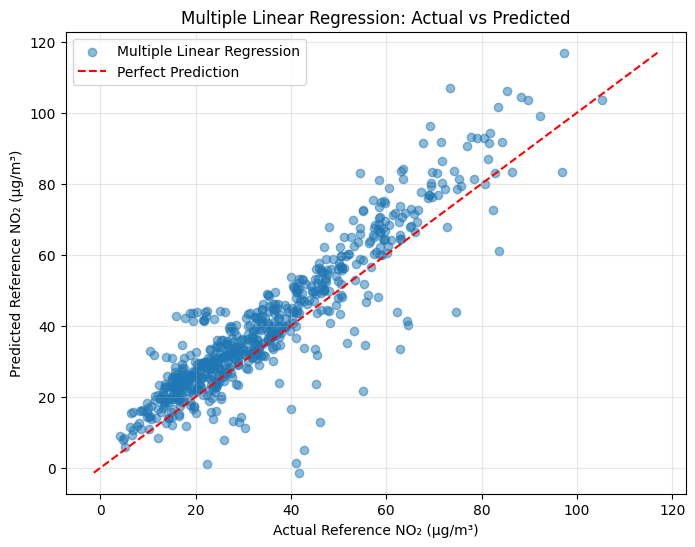

In [71]:
# Section 4.8 - Actual vs Predicted NO2

import matplotlib.pyplot as plt

# Set the figure dimensions
plt.figure(figsize=(8, 6))

# Plot a scatter plot of actual values against Multiple Linear Regression predictions
plt.scatter(
    y_test,
    multiple_predictions,
    alpha=0.5,                  # Transparency of points
    label="Multiple Linear Regression"
)

# Calculate coordinate boundaries for the diagonal reference line
lower = min(y_test.min(), multiple_predictions.min())
upper = max(y_test.max(), multiple_predictions.max())

# Plot a red dashed line representing ideal/perfect predictions (y = x)
plt.plot(
    [lower, upper],
    [lower, upper],
    "r--",                      # Red dashed line style
    label="Perfect Prediction"
)

# Configure chart labels, title, legend, and grids
plt.xlabel("Actual Reference NO₂ (µg/m³)")
plt.ylabel("Predicted Reference NO₂ (µg/m³)")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 5. Model Evaluation and Comparison

This section evaluates the performance of the regression
models developed in Section 4.

The main focus is comparing Simple Linear Regression
with Multiple Linear Regression to investigate whether
additional sensor and environmental variables improve
prediction accuracy.

Random Forest and Gradient Boosting are also evaluated
to investigate whether nonlinear models provide better
predictions of reference NO₂ concentrations.

In [72]:
# Section 5.1 - Evaluate Multiple Linear Regression by Sensor

# Create a working copy of the test DataFrame to prevent modifying the original
temp_test_df = test_df.copy()

# If Sensor_ID column is missing from single sensor datasets, default to 'ASE4'
if "Sensor_ID" not in temp_test_df.columns:
    temp_test_df["Sensor_ID"] = "ASE4"

# Isolate sensor identifiers and site location indicators
sensor_evaluation = temp_test_df[
    ["Sensor_ID", "Location"]
].copy()

# Map actual ground truth measurements and predicted targets to evaluate errors
sensor_evaluation["Actual_NO2"] = y_test.to_numpy()
sensor_evaluation["Predicted_NO2"] = multiple_predictions

# Compute absolute error of the prediction
sensor_evaluation["Absolute_Error"] = (
    sensor_evaluation["Actual_NO2"] -
    sensor_evaluation["Predicted_NO2"]
).abs()

# Aggregate mean absolute error and observations count for each sensor and location
sensor_mae = (
    sensor_evaluation
    .groupby(["Sensor_ID", "Location"])["Absolute_Error"]
    .agg(["mean", "count"]
).reset_index())

# Rename aggregated calculation metrics for display
sensor_mae = sensor_mae.rename(
    columns={
        "mean": "MAE",
        "count": "Observations"
    }
)

# Display aggregated results rounded to 3 decimal places
display(sensor_mae.round(3))

,Sensor_ID,Location,MAE,Observations
0,ASE4,QDP,7.354,650


In [73]:
# Section 5.2 - Model Evaluation Libraries

# Import standard libraries for plotting and DataFrame processing
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import metrics from Scikit-Learn to evaluate regression accuracy
from sklearn.metrics import (
    mean_absolute_error,    # Computes Mean Absolute Error (MAE)
    mean_squared_error,     # Computes Mean Squared Error (MSE)
    r2_score                # Computes R² (Coefficient of Determination)
)

In [74]:
# Section 5.3 - Evaluate All Models

# Check if Gradient Boosting model needs to be initialized and trained in this scope
if "boosting_predictions" not in globals():
    print("Training Gradient Boosting model first...")
    gradient_boosting = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        ))
    ])
    gradient_boosting.fit(X_train, y_train)
    boosting_predictions = gradient_boosting.predict(X_test)

# Create a dictionary to map model names to their respective predicted arrays
model_predictions = {
    "Simple Linear Regression": simple_predictions,
    "Multiple Linear Regression": multiple_predictions,
    "Random Forest": forest_predictions,
    "Gradient Boosting": boosting_predictions
}

# List container to store computed evaluation dictionary records
evaluation_results = []

# Iterate through each model and calculate standard performance metrics
for name, predictions in model_predictions.items():

    # Calculate Mean Absolute Error (MAE)
    mae = mean_absolute_error(y_test, predictions)

    # Calculate Root Mean Squared Error (RMSE)
    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    # Calculate R-squared (R2) score
    r2 = r2_score(y_test, predictions)

    # Append the metric record to our evaluation log
    evaluation_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# Build a DataFrame containing performance metrics for all models
results_df = pd.DataFrame(evaluation_results)

# Display metrics rounded to 3 decimal places
display(results_df.round(3))

,Model,MAE,RMSE,R2
0,Simple Linear Regression,7.769,11.105,0.647
1,Multiple Linear Regression,7.354,9.600,0.736
2,Random Forest,4.840,6.844,0.866
3,Gradient Boosting,4.663,6.179,0.891


,Model,MAE,RMSE,R2
0,Simple Linear Regression,7.769,11.105,0.647
1,Multiple Linear Regression,7.354,9.600,0.736


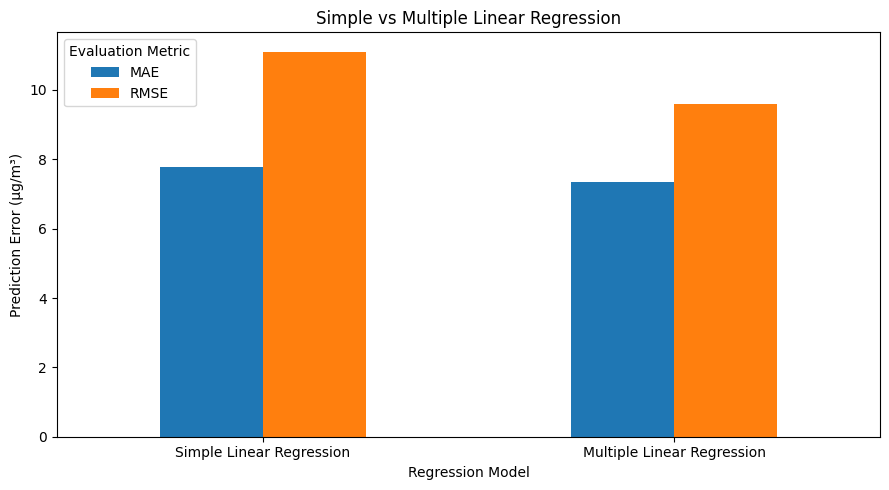

In [75]:
# Section 5.4 - Linear Regression Comparison

# Extract evaluation results strictly for the simple and multiple linear models
linear_comparison = results_df[
    results_df["Model"].isin([
        "Simple Linear Regression",
        "Multiple Linear Regression"
    ])
]

# Render the subset comparison table
display(linear_comparison.round(3))

# Set Model as index and filter out MAE and RMSE metrics for plotting
linear_plot = linear_comparison.set_index("Model")[
    ["MAE", "RMSE"]
]

# Generate a bar plot comparison of baseline error metrics
linear_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

# Configure chart details, axis titles, and display options
plt.title("Simple vs Multiple Linear Regression")
plt.ylabel("Prediction Error (µg/m³)")
plt.xlabel("Regression Model")
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metric")
plt.tight_layout()
plt.show()

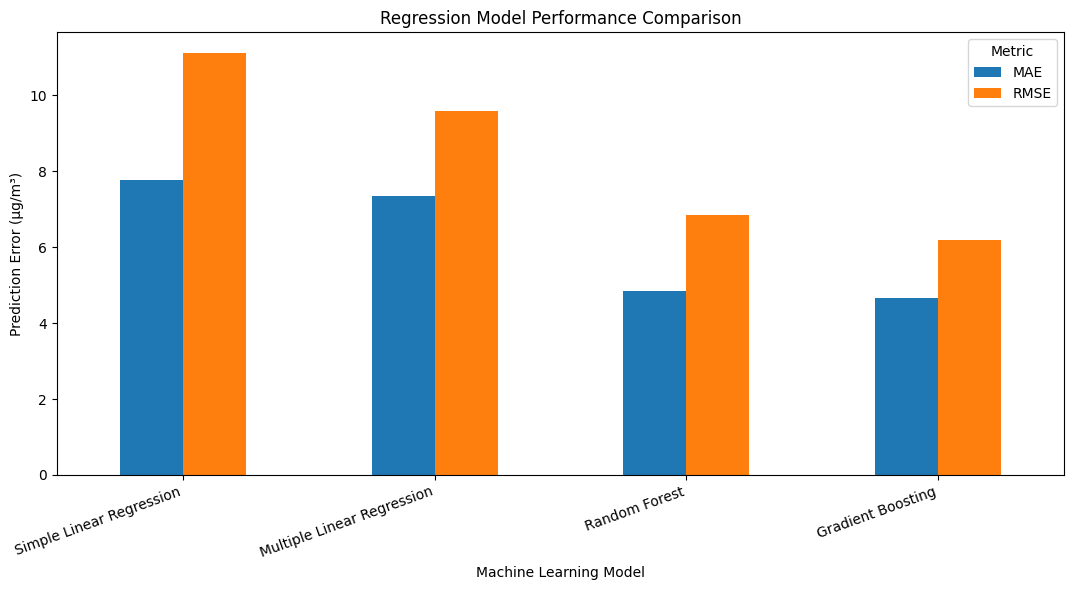

In [76]:
# Section 5.5 - All Model Comparison

# Format error metrics (MAE and RMSE) for all models into a chartable structure
comparison_plot = results_df.set_index("Model")[
    ["MAE", "RMSE"]
]

# Plot a comparative side-by-side bar chart of error metrics for all algorithms
comparison_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

# Adjust titles, axis text configurations, and optimize layouts
plt.title("Regression Model Performance Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Prediction Error (µg/m³)")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

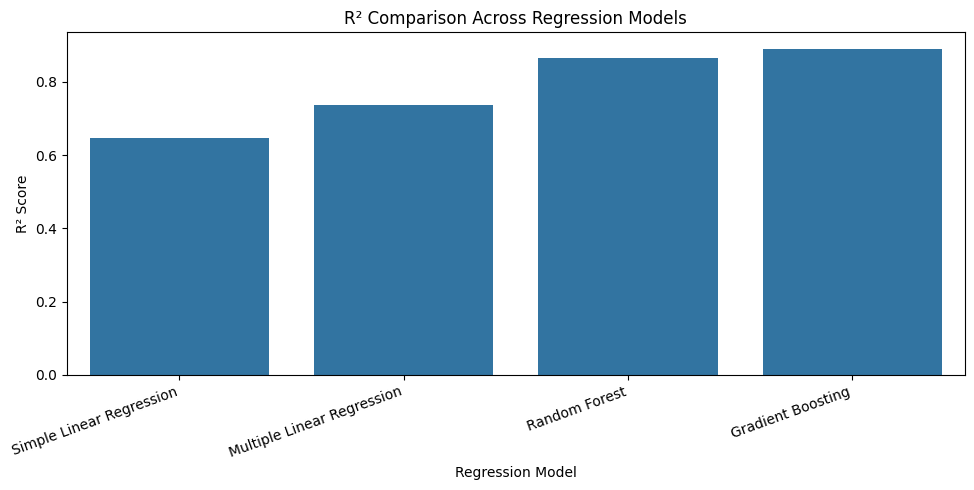

In [77]:
# Section 5.6 - R² Comparison

# Initialize figure size
plt.figure(figsize=(10, 5))

# Generate a bar chart showing the R² score of each model
sns.barplot(
    data=results_df,
    x="Model",
    y="R2"
)

# Set chart title, labels, and rotate the labels on the x-axis
plt.title("R² Comparison Across Regression Models")
plt.xlabel("Regression Model")
plt.ylabel("R² Score")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

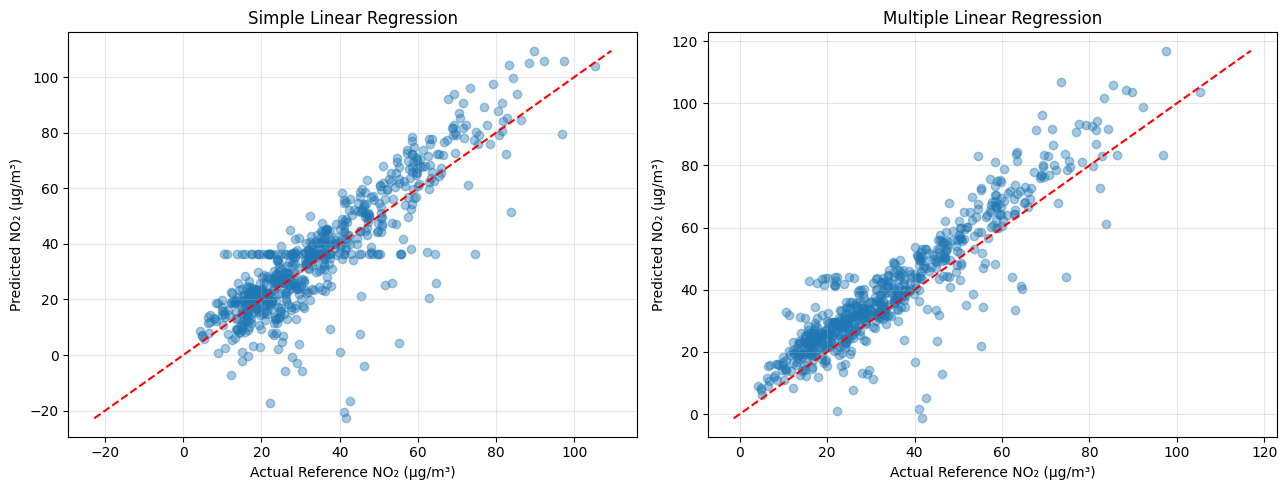

In [78]:
# Section 5.7 - Linear Regression Predictions

# Set up a grid with 1 row and 2 columns for side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Build list of scenarios for visualization
predictions_to_plot = [
    ("Simple Linear Regression", simple_predictions),
    ("Multiple Linear Regression", multiple_predictions)
]

# Draw subplot scatter charts for both linear regression models
for ax, (name, predictions) in zip(
    axes, predictions_to_plot
):
    # Create the scatter plot of actual vs predicted targets
    ax.scatter(
        y_test,
        predictions,
        alpha=0.4
    )

    # Generate perfect prediction reference limits
    lower = min(y_test.min(), predictions.min())
    upper = max(y_test.max(), predictions.max())

    # Overlay a diagonal red dashed ideal reference line
    ax.plot(
        [lower, upper],
        [lower, upper],
        "r--"
    )

    # Configure details of the subplot axes
    ax.set_title(name)
    ax.set_xlabel("Actual Reference NO₂ (µg/m³)")
    ax.set_ylabel("Predicted NO₂ (µg/m³)")
    ax.grid(alpha=0.3)

# Adjust and display layout
plt.tight_layout()
plt.show()

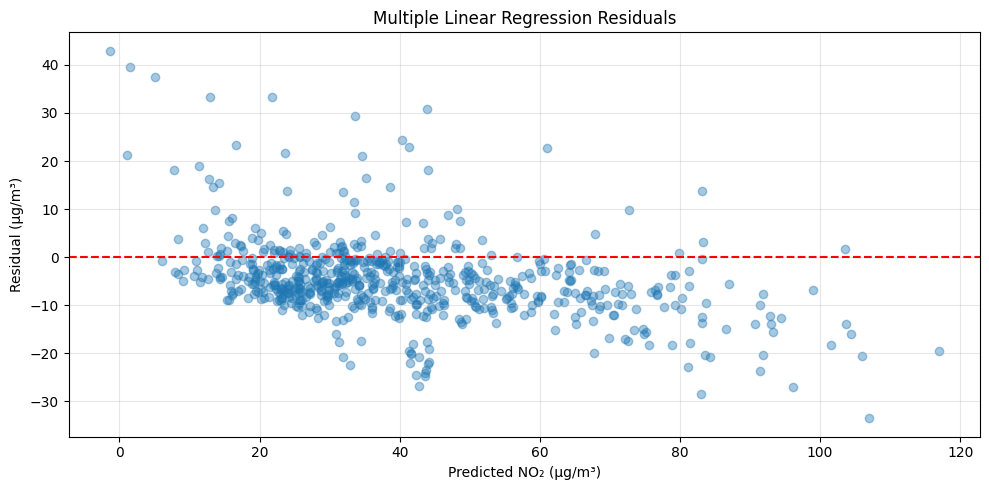

In [79]:
# Section 5.8 - Residual Analysis

# Compute model residuals (Actual minus Predicted)
residuals = y_test.to_numpy() - multiple_predictions

# Define scatter plot figure window
plt.figure(figsize=(10, 5))

# Create a residual scatter plot to check for heteroscedasticity
plt.scatter(
    multiple_predictions,
    residuals,
    alpha=0.4
)

# Draw a horizontal zero-residual reference line
plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

# Configure chart title and labels
plt.title("Multiple Linear Regression Residuals")
plt.xlabel("Predicted NO₂ (µg/m³)")
plt.ylabel("Residual (µg/m³)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [80]:
# Section 5.9 - Identify Best Model

# Locate the model configuration that minimizes Mean Absolute Error (MAE)
best_model = results_df.loc[
    results_df["MAE"].idxmin()
]

# Display the top-performing model's name
print("Best model based on MAE:")
print(best_model["Model"])

# Output model performance statistics
print("\nPerformance:")
print("MAE:", round(best_model["MAE"], 3))
print("RMSE:", round(best_model["RMSE"], 3))
print("R²:", round(best_model["R2"], 3))

Best model based on MAE:
Gradient Boosting

Performance:
MAE: 4.663
RMSE: 6.179
R²: 0.891
